# Census-Income (KDD): EDA

**結論：年によって記録が異なる列と定数列を除き、33特徴量で比較する。** 以下で欠損・分布・関連を確認する。対象はUCIの2ファイルを結合した18歳以上215,574件。

実行環境：Colab/Kaggle。データがなければ最初のセルで取得する。

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "data_loader.py").exists() else cwd.parent
assert (repo_root / "src" / "data_loader.py").exists(), "リポジトリ直下または notebooks/ で実行してください"
data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)

df = pd.read_csv(data_path, skipinitialspace=True)
assert df.shape == (215_574, 41)
assert "instance_weight" not in df.columns
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head(3))

Rows: 215,574 | Columns: 41


,age,class_of_worker,detailed_industry_recode,detailed_occupation_recode,education,wage_per_hour,enroll_in_edu_inst_last_wk,marital_stat,major_industry_code,major_occupation_code,...,country_of_birth_father,country_of_birth_mother,country_of_birth_self,citizenship,own_business_or_self_employed,fill_inc_questionnaire_for_veterans_admin,veterans_benefits,weeks_worked_in_year,year,income_class
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,0,95,- 50000.
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,...,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,52,94,- 50000.
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,...,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0,Not in universe,2,0,95,- 50000.


## 1. 欠損値の確認

**方針：`?`のみ欠損。** `Not in universe`は対象外を示すカテゴリとして残す。

In [2]:
# 文字列列の前後の空白を除き、? だけを欠損値にする。
text_cols = df.select_dtypes(include=["object", "str"]).columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
df[text_cols] = df[text_cols].replace("?", pd.NA)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_rate_pct": df.isna().mean().mul(100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing[missing.missing_count > 0])

,missing_count,missing_rate_pct
migration_code_change_in_msa,107895,50.05
migration_code_change_in_reg,107895,50.05
migration_code_move_within_reg,107895,50.05
migration_prev_res_in_sunbelt,107895,50.05
country_of_birth_father,8361,3.88
country_of_birth_mother,7539,3.50
country_of_birth_self,4511,2.09
hispanic_origin,972,0.45
state_of_previous_residence,778,0.36


## 2. `Not in universe` の割合（定数列を確認）

In [3]:
not_in_universe = pd.DataFrame({
    "count": df.eq("Not in universe").sum(),
    "rate_pct": df.eq("Not in universe").mean().mul(100).round(2),
}).sort_values("count", ascending=False)
display(not_in_universe[not_in_universe["count"] > 0])

,count,rate_pct
family_members_under_18,215574,100.00
fill_inc_questionnaire_for_veterans_admin,212568,98.61
reason_for_unemployment,207175,96.10
enroll_in_edu_inst_last_wk,204565,94.89
region_of_previous_residence,198479,92.07
state_of_previous_residence,198479,92.07
member_of_labor_union,187686,87.06
migration_prev_res_in_sunbelt,90584,42.02
major_occupation_code,70991,32.93
class_of_worker,70700,32.80


## 3. 数値コード5列をカテゴリ型に修正

In [4]:
# .names では nominal とされるが、CSVから整数として読まれる列。
numeric_categorical = [
    "detailed_industry_recode", "detailed_occupation_recode",
    "own_business_or_self_employed", "veterans_benefits", "year",
]
print("Before:")
display(df[numeric_categorical].dtypes.to_frame("dtype"))
for col in numeric_categorical:
    df[col] = df[col].astype("string")
print("After:")
display(df[numeric_categorical].dtypes.to_frame("dtype"))

numeric_cols = [
    "age", "wage_per_hour", "capital_gains", "capital_losses",
    "dividends_from_stocks", "num_persons_worked_for_employer",
    "weeks_worked_in_year",
]
assert set(df.select_dtypes(include="number").columns) == set(numeric_cols)
display(df[numeric_cols].describe(percentiles=[.5, .95, .99]).T)

Before:


,dtype
detailed_industry_recode,int64
detailed_occupation_recode,int64
own_business_or_self_employed,int64
veterans_benefits,int64
year,int64


After:


,dtype
detailed_industry_recode,string
detailed_occupation_recode,string
own_business_or_self_employed,string
veterans_benefits,string
year,string


,count,mean,std,min,50%,95%,99%,max
age,215574.0,44.700080,17.671250,18.0,42.0,77.00,87.0,90.0
wage_per_hour,215574.0,75.164482,318.238453,0.0,0.0,688.35,1575.0,9999.0
capital_gains,215574.0,598.140778,5491.436919,0.0,0.0,991.00,14344.0,99999.0
capital_losses,215574.0,50.151925,313.866401,0.0,0.0,0.00,1974.0,4608.0
dividends_from_stocks,215574.0,271.303158,2278.620466,0.0,0.0,778.00,6000.0,99999.0
num_persons_worked_for_employer,215574.0,2.644939,2.399206,0.0,2.0,6.00,6.0,6.0
weeks_worked_in_year,215574.0,31.705679,23.468964,0.0,50.0,52.00,52.0,52.0


## 4. 高所得は8.61%（クラス不均衡）

In [5]:
class_counts = df["income_class"].value_counts(dropna=False)
display(pd.DataFrame({
    "count": class_counts,
    "rate_pct": class_counts.div(len(df)).mul(100).round(2),
}))

,count,rate_pct
income_class,,
- 50000.,197008,91.39
50000+.,18566,8.61


## 5. 数値7列のクラス別ヒストグラム

**目的：クラス別の分布を比較する。** 金額系の`log1p`は表示用で、データは変えない。

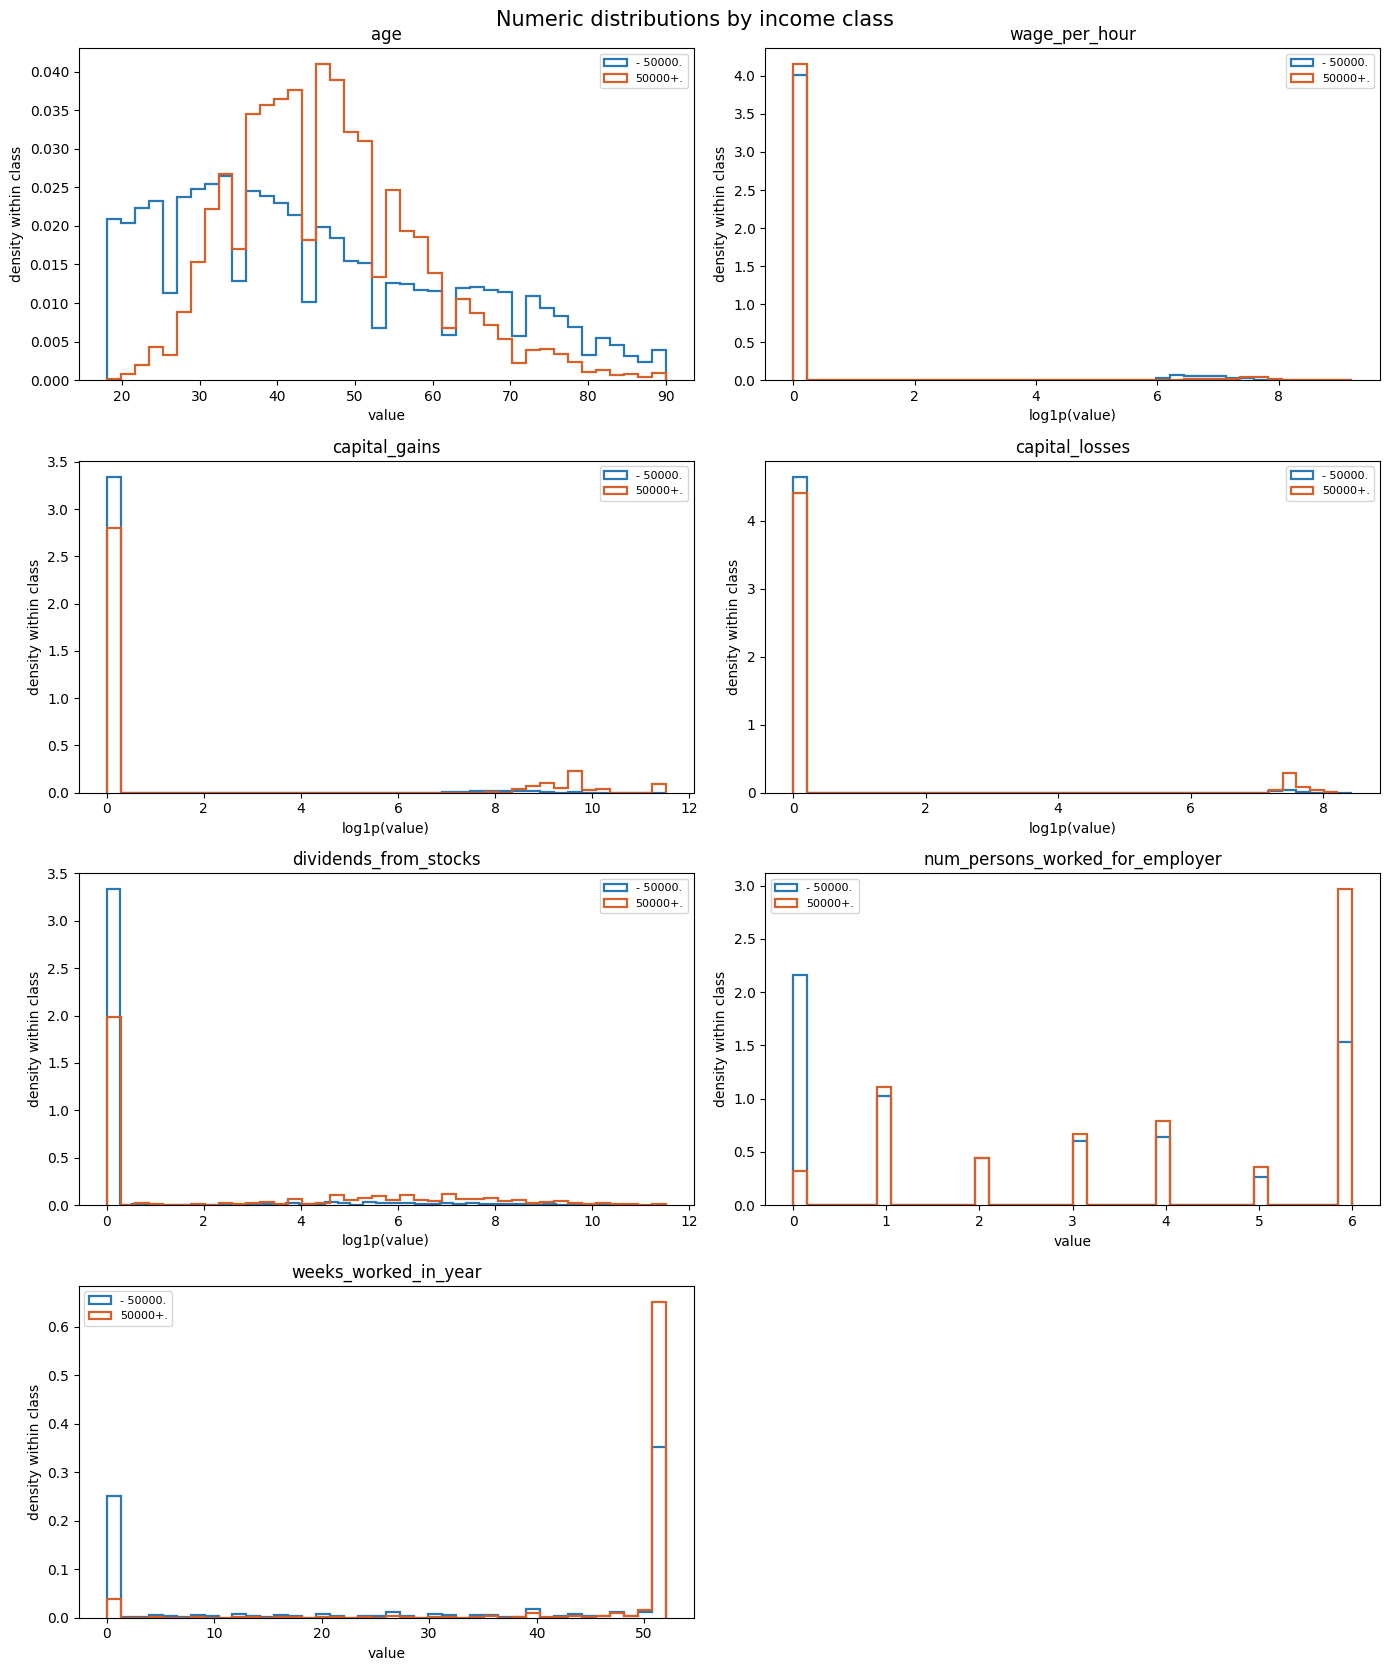

In [6]:
skewed_cols = {"wage_per_hour", "capital_gains", "capital_losses", "dividends_from_stocks"}
classes = sorted(df["income_class"].dropna().unique())
colors = ["#2878B5", "#D66027"]
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, col in zip(axes.flat, numeric_cols):
    for label, color in zip(classes, colors):
        values = df.loc[df["income_class"] == label, col].dropna().to_numpy()
        if col in skewed_cols:
            values = np.log1p(values)
        ax.hist(values, bins=40, density=True, histtype="step", linewidth=1.6,
                color=color, label=label)
    ax.set_title(col)
    ax.set_xlabel("log1p(value)" if col in skewed_cols else "value")
    ax.set_ylabel("density within class")
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Numeric distributions by income class", fontsize=15)
fig.tight_layout()
plt.show()

## 6. 数値7列のクラス別箱ひげ図

**目的：分布の中心と広がりを比べる。** 外れ値の点は非表示。金額系の`log1p`は表示用。

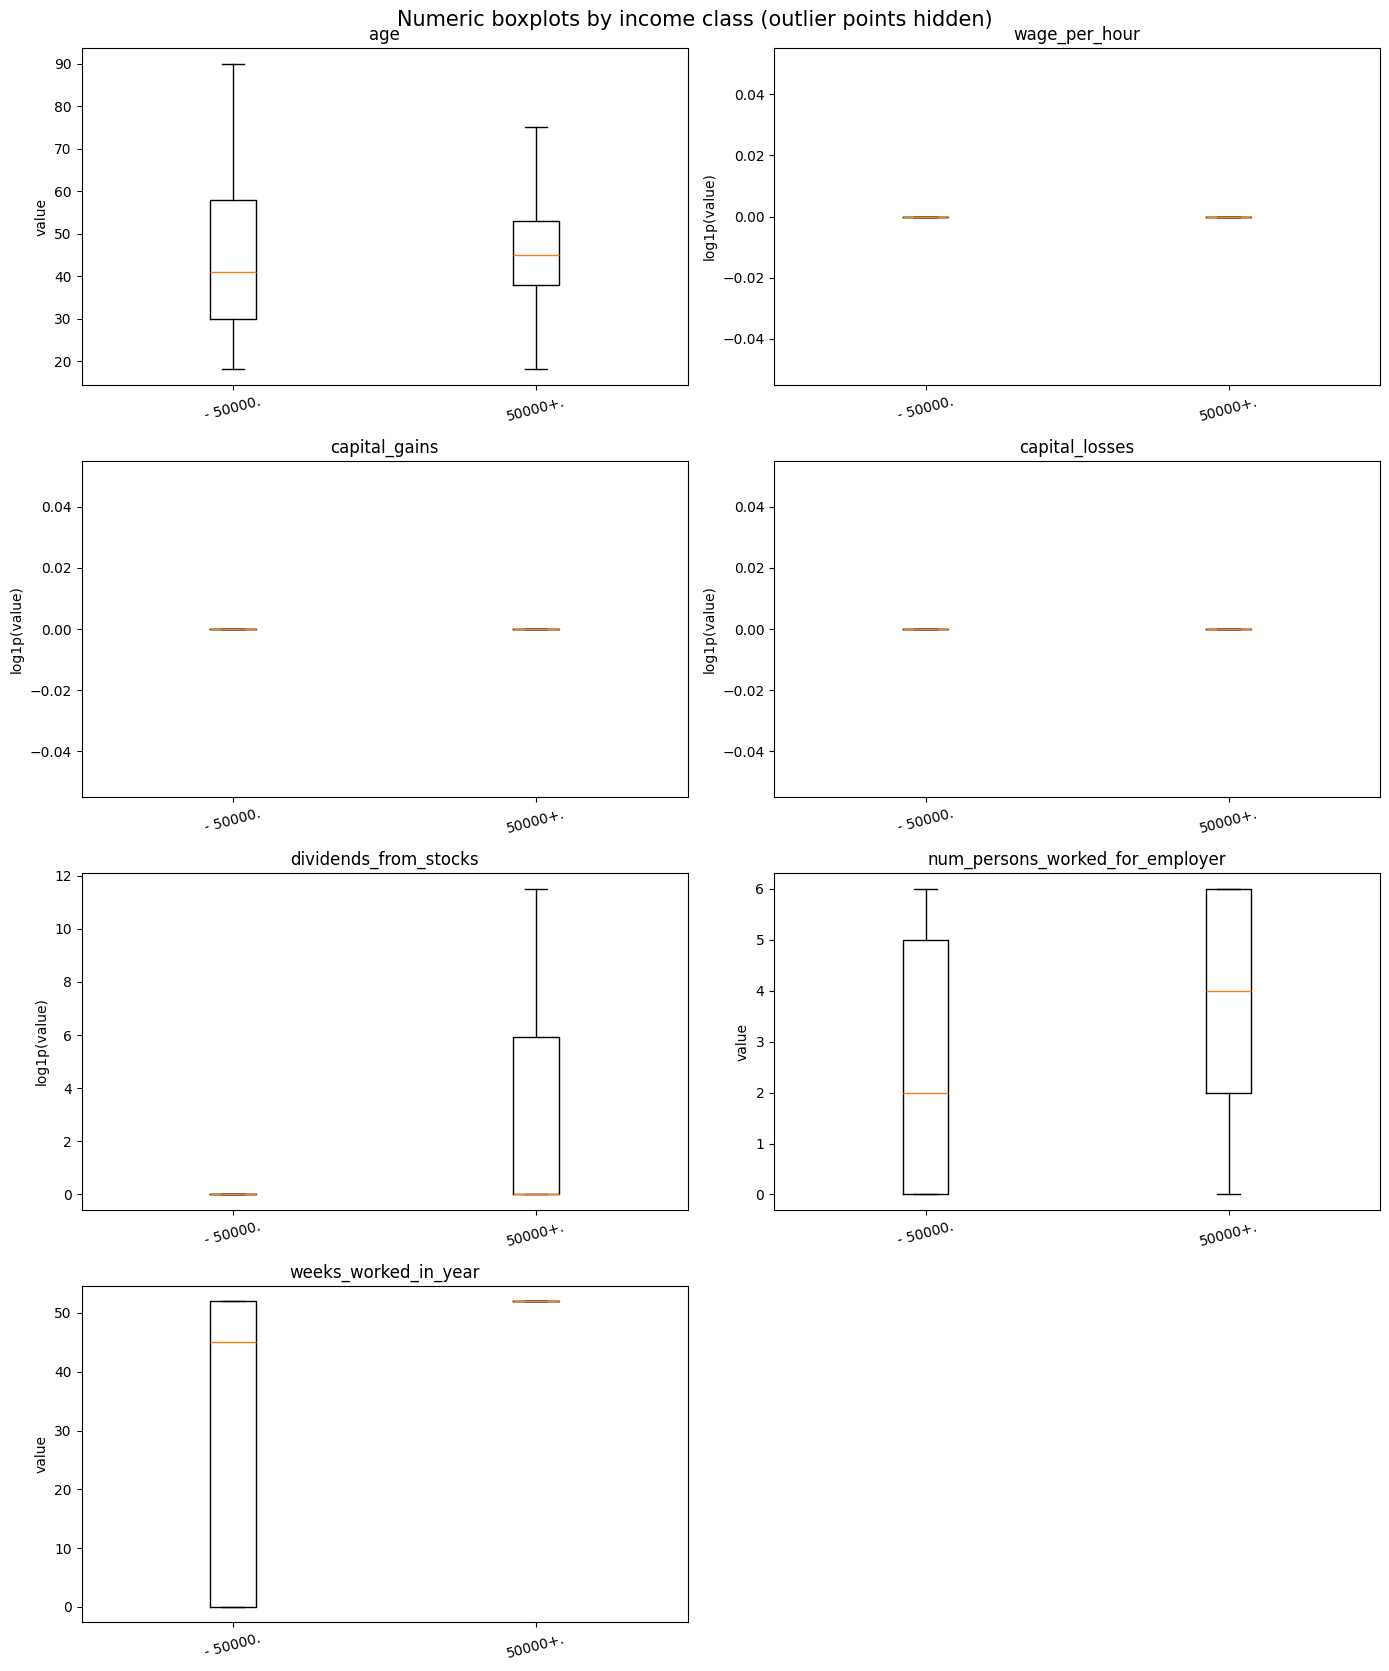

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, col in zip(axes.flat, numeric_cols):
    groups = []
    for label in classes:
        values = df.loc[df["income_class"] == label, col].dropna().to_numpy()
        groups.append(np.log1p(values) if col in skewed_cols else values)
    ax.boxplot(groups, tick_labels=classes, showfliers=False)
    ax.set_title(col)
    ax.set_ylabel("log1p(value)" if col in skewed_cols else "value")
    ax.tick_params(axis="x", labelrotation=15)
axes.flat[-1].axis("off")
fig.suptitle("Numeric boxplots by income class (outlier points hidden)", fontsize=15)
fig.tight_layout()
plt.show()

### 外れ値の要約

**結論：金額列の外れ値は一括削除しない。** 0が多く全行のIQRが0になるため、非ゼロ値での外れ値率と、0か否かの高所得率を併記する。99,999が上限コードかは未確認。

In [8]:
def iqr_outlier_rate(values):
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr == 0:
        return np.nan  # IQRが0になる列ではIQRルールを適用できない
    return ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean() * 100

is_high = df["income_class"].eq("50000+.")
outlier_rows = []
for col in numeric_cols:
    values = df[col]
    nonzero = values > 0
    outlier_rows.append({
        "feature": col,
        "zero_rate_pct": (~nonzero).mean() * 100,
        "IQR_outlier_rate_all_pct": iqr_outlier_rate(values),
        "IQR_outlier_rate_nonzero_pct": iqr_outlier_rate(values[nonzero]),
        "max": values.max(),
        "rows_at_max": int(values.eq(values.max()).sum()),
        "high_income_rate_if_nonzero_pct": is_high[nonzero].mean() * 100,
        "high_income_rate_if_zero_pct": is_high[~nonzero].mean() * 100,
    })
display(pd.DataFrame(outlier_rows).set_index("feature").round(2))

,zero_rate_pct,IQR_outlier_rate_all_pct,IQR_outlier_rate_nonzero_pct,max,rows_at_max,high_income_rate_if_nonzero_pct,high_income_rate_if_zero_pct
feature,,,,,,,
age,0.00,0.0,0.00,90,1098,8.61,NaN
wage_per_hour,92.44,NaN,3.73,9999,1,4.95,8.91
capital_gains,94.88,NaN,7.19,99999,578,32.60,7.32
capital_losses,97.36,NaN,8.71,4608,8,30.65,8.01
dividends_from_stocks,85.42,NaN,12.45,99999,31,25.38,5.75
num_persons_worked_for_employer,30.06,0.0,0.00,6,53424,11.71,1.40
weeks_worked_in_year,30.06,0.0,19.05,52,104663,11.71,1.40


## 7. 数値7列の相関（就労関連2列に関連）

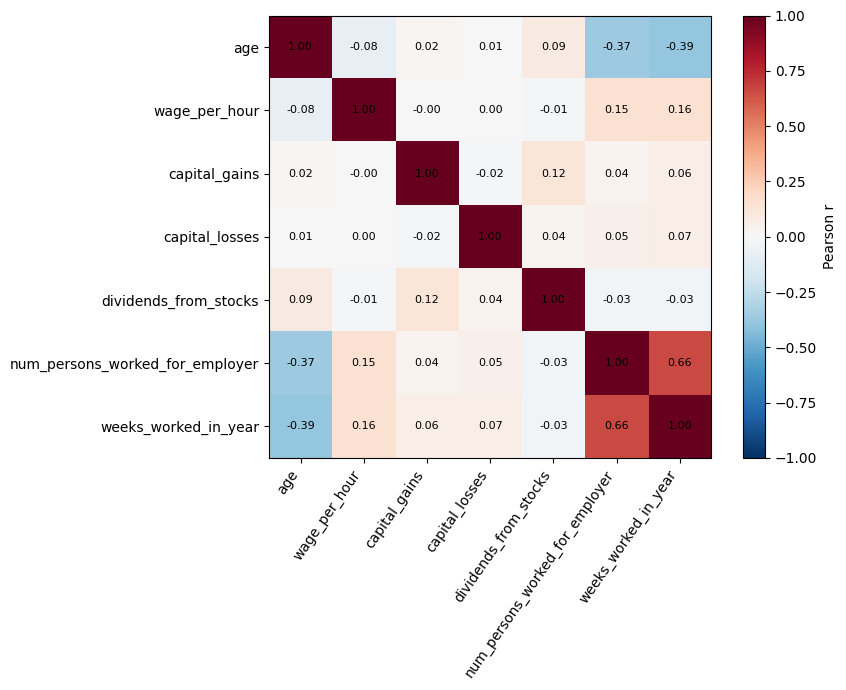

In [9]:
corr = df[numeric_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(9, 7))
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(numeric_cols)), labels=numeric_cols, rotation=55, ha="right")
ax.set_yticks(range(len(numeric_cols)), labels=numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(heat, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

## 8. カテゴリ列どうしの関連（Cramér's V）

**結論：強い関連があっても即座には列を削除しない。** Cramér's V（0～1）をカテゴリ列・目的変数間で計算する。欠損は`Missing`として数え、定数列は除く。

Excluded constant columns: ['family_members_under_18']


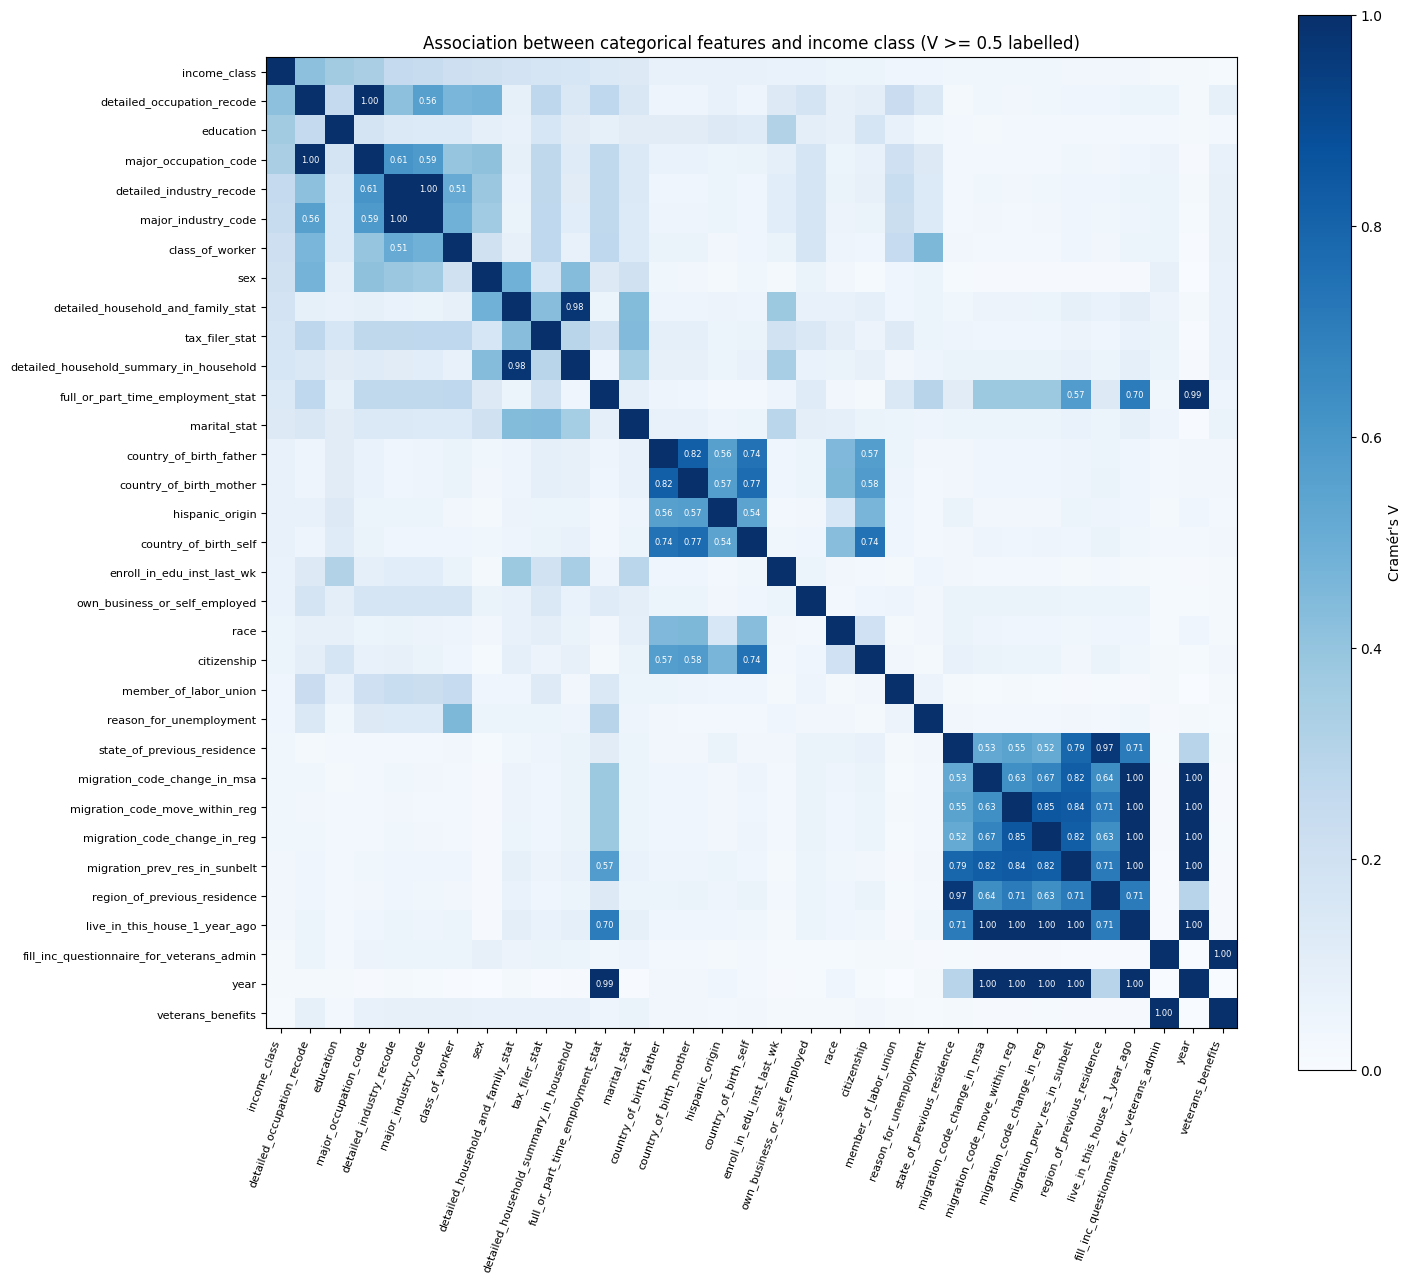

Most associated feature pairs:


cramers_v
migration_code_change_in_reg              year                                         1.000
fill_inc_questionnaire_for_veterans_admin veterans_benefits                            1.000
detailed_industry_recode                  major_industry_code                          1.000
live_in_this_house_1_year_ago             migration_code_change_in_reg                 1.000
                                          migration_prev_res_in_sunbelt                1.000
detailed_occupation_recode                major_occupation_code                        1.000
migration_code_move_within_reg            year                                         1.000
migration_prev_res_in_sunbelt             year                                         1.000
live_in_this_house_1_year_ago             migration_code_change_in_msa                 1.000
                                          migration_code_move_within_reg               1.000
                                          year                                         1.000
migration_code_change_in_msa              year                                         1.000
full_or_part_time_employment_stat         year                                         0.995
detailed_household_and_family_stat        detailed_household_summary_in_household      0.975
region_of_previous_residence              state_of_previous_residence                  0.967

Association with income_class:


,cramers_v
detailed_occupation_recode,0.415
education,0.360
major_occupation_code,0.337
detailed_industry_recode,0.253
major_industry_code,0.236
class_of_worker,0.215
sex,0.195
detailed_household_and_family_stat,0.182
tax_filer_stat,0.169
detailed_household_summary_in_household,0.163


In [10]:
from scipy.stats.contingency import association

categorical_cols = [c for c in df.columns if c not in numeric_cols and c != "income_class"]
constant_cols = [c for c in categorical_cols if df[c].nunique(dropna=False) == 1]
print("Excluded constant columns:", constant_cols)
cat_frame = df[[c for c in categorical_cols if c not in constant_cols] + ["income_class"]]
codes = {c: pd.factorize(cat_frame[c].fillna("Missing"))[0] for c in cat_frame.columns}

def cramers_v(a, b):
    n_a, n_b = a.max() + 1, b.max() + 1
    table = np.bincount(a * n_b + b, minlength=n_a * n_b).reshape(n_a, n_b)
    return association(table, method="cramer")

names = list(codes)
cramer = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for i, left in enumerate(names):
    for right in names[i + 1:]:
        cramer.loc[left, right] = cramer.loc[right, left] = cramers_v(codes[left], codes[right])

order = cramer["income_class"].sort_values(ascending=False).index
cramer = cramer.loc[order, order]
fig, ax = plt.subplots(figsize=(15, 13))
heat = ax.imshow(cramer, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(order)), labels=order, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), labels=order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j and cramer.iloc[i, j] >= 0.5:
            ax.text(j, i, f"{cramer.iloc[i, j]:.2f}", ha="center", va="center",
                    fontsize=6, color="white")
fig.colorbar(heat, ax=ax, label="Cramér's V")
ax.set_title("Association between categorical features and income class (V >= 0.5 labelled)")
fig.tight_layout()
plt.show()

pairs = cramer.drop(index="income_class", columns="income_class").stack()
pairs = pairs[[a < b for a, b in pairs.index]].sort_values(ascending=False)
print("Most associated feature pairs:")
display(pairs.head(15).round(3).to_frame("cramers_v"))
print("Association with income_class:")
display(cramer["income_class"].drop("income_class").round(3).to_frame("cramers_v"))

## 観察メモ

**結論：33特徴量を基準にし、外れ値は一括削除しない。**

- **除外：** 1995年に全件欠損するmigration 4列、成人では定数の`family_members_under_18`、片方の年で実質的に定数の`live_in_this_house_1_year_ago`と`full_or_part_time_employment_stat`。後者2列は情報のある年の信号を失う代償がある。
- **欠損：** `?`のみ欠損扱い。`Not in universe`はカテゴリとして残す。出生国3列の欠損率は2.09～3.88%。
- **クラス：** 高所得18,566件（8.61%）。層化分割し、主指標はAP。重み付けは訓練CVで判断する。
- **数値：** 金額4列は0が85～97%。`capital_gains`の99,999は578件で、上限コードかは未確認。外れ値削除はせず、raw/`log1p`を比較する。
- **関連：** 就労関連2列のPearson rは約0.66。詳細/大分類の職業・産業列はCramér's V=1.00だが、同一情報とは限らないため削除しない。
- **次段階：** 補完・標準化・one-hot・MIは訓練側だけでfit。PCAは可視化に使用し、最終テストは判断に使わない。